# BirdCLEF 2026: Comprehensive Exploratory Data Analysis

In this notebook, we explore the BirdCLEF 2026 dataset to understand the fundamental characteristics of the bird call audio data and the associated metadata. 

Our goal is to uncover the underlying data distributions, identify potential challenges (such as data imbalance or varying audio quality), and derive data-driven insights that will naturally inform our feature engineering and modeling strategies.



## 1. Setup & Data Loading
Loading libraries and dataset sizes.


In [1]:
import os
import re
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import soundfile as sf
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", context="notebook", palette="muted")

# Kaggle Paths
DATA_DIR = "/kaggle/input/competitions/birdclef-2026"

TRAIN_CSV = os.path.join(DATA_DIR, "train.csv")
TAXONOMY_CSV = os.path.join(DATA_DIR, "taxonomy.csv")
TRAIN_AUDIO_DIR = os.path.join(DATA_DIR, "train_audio")
SOUNDSCAPE_DIR = os.path.join(DATA_DIR, "train_soundscapes")

train = pd.read_csv(TRAIN_CSV)
taxonomy = pd.read_csv(TAXONOMY_CSV)

print(f"Total training samples: {len(train)}")
print(f"Total species in taxonomy: {len(taxonomy)}")
display(train.head(3))


Total training samples: 35549
Total species in taxonomy: 234


,primary_label,secondary_labels,type,latitude,longitude,scientific_name,common_name,class_name,inat_taxon_id,author,license,rating,url,filename,collection
0,1161364,[],[],-22.7562,-46.8666,Guyalna cuta,Guyalna cuta,Insecta,1161364,Lucas Barbosa,cc-by-nc,0.0,https://static.inaturalist.org/sounds/1216197....,1161364/iNat1216197.ogg,iNat
1,1161364,[],[],-22.7558,-46.8700,Guyalna cuta,Guyalna cuta,Insecta,1161364,Lucas Barbosa,cc-by-nc,0.0,https://static.inaturalist.org/sounds/1114648....,1161364/iNat1114648.ogg,iNat
2,1161364,[],[],-22.7547,-46.8728,Guyalna cuta,Guyalna cuta,Insecta,1161364,Lucas Barbosa,cc-by-nc,0.0,https://static.inaturalist.org/sounds/810195.m...,1161364/iNat810195.ogg,iNat


## 2. Species Distribution Analysis
Checking target class distribution.


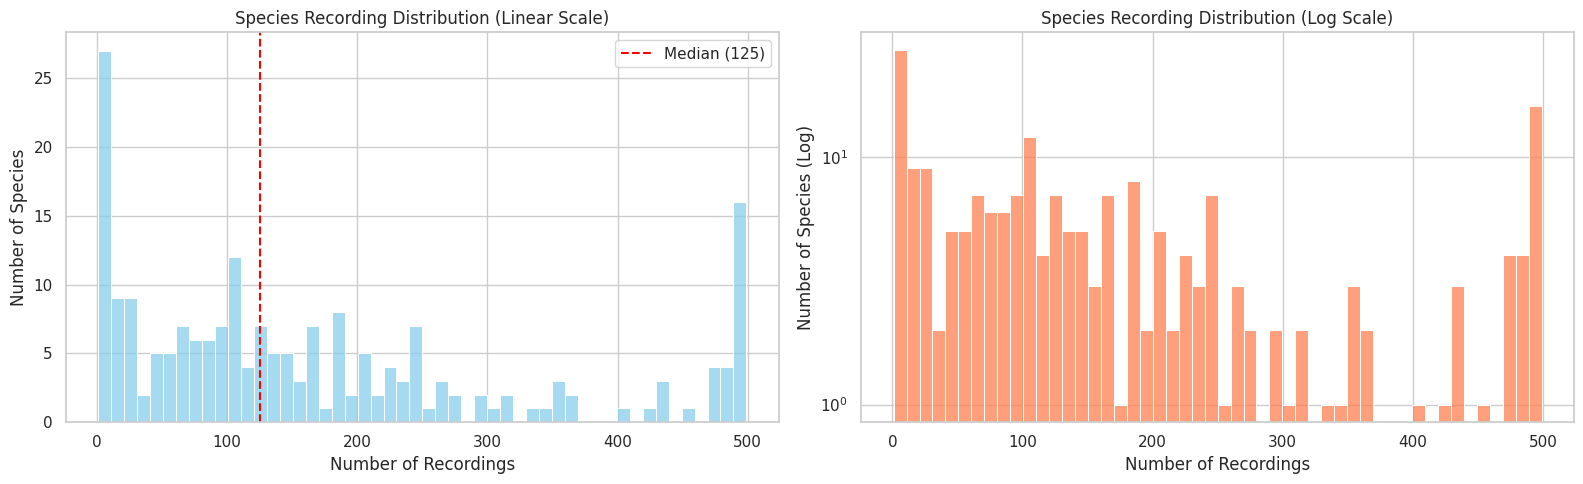

In [2]:
species_counts = train['primary_label'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Linear Scale
sns.histplot(species_counts, bins=50, ax=axes[0], color='skyblue')
axes[0].set_title("Species Recording Distribution (Linear Scale)")
axes[0].set_xlabel("Number of Recordings")
axes[0].set_ylabel("Number of Species")
axes[0].axvline(species_counts.median(), color="red", linestyle="--", label=f"Median ({species_counts.median():.0f})")
axes[0].legend()

# Plot 2: Log Scale
sns.histplot(species_counts, bins=50, ax=axes[1], color='coral')
axes[1].set_yscale("log")
axes[1].set_title("Species Recording Distribution (Log Scale)")
axes[1].set_xlabel("Number of Recordings")
axes[1].set_ylabel("Number of Species (Log)")

plt.tight_layout()
plt.show()


In [3]:
# Let's quantify the long tail
rare_thresholds = [5, 10, 20, 50]
for t in rare_thresholds:
    n_species = (species_counts < t).sum()
    print(f"Species with fewer than {t} recordings: {n_species} ({(n_species/len(species_counts))*100:.1f}%)")

print("\nThe dataset has extreme class imbalance (long-tail distribution).")
print("Standard models will likely overfit on the majority classes and ignore rare birds.")
print("We should use Class Weights and Data Augmentation to help learn rare species.")


Species with fewer than 5 recordings: 14 (6.8%)
Species with fewer than 10 recordings: 25 (12.1%)
Species with fewer than 20 recordings: 36 (17.5%)
Species with fewer than 50 recordings: 52 (25.2%)

The dataset has extreme class imbalance (long-tail distribution).
Standard models will likely overfit on the majority classes and ignore rare birds.
We should use Class Weights and Data Augmentation to help learn rare species.


### Audio Quality Analysis
Exploring `rating` distribution to check audio quality.


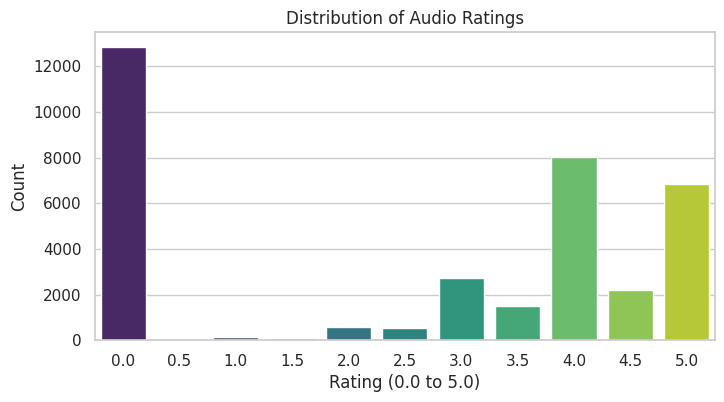

While many samples have high ratings, a lot of audio is rated below 2.0.
Training on noisy data might degrade performance. Consider filtering out recordings with rating < 2.0.


In [4]:
plt.figure(figsize=(8, 4))
sns.countplot(data=train, x='rating', palette='viridis')
plt.title("Distribution of Audio Ratings")
plt.xlabel("Rating (0.0 to 5.0)")
plt.ylabel("Count")
plt.show()

print("While many samples have high ratings, a lot of audio is rated below 2.0.")
print("Training on noisy data might degrade performance. Consider filtering out recordings with rating < 2.0.")


## 3. Audio Duration Exploration
Checking audio file lengths.


Checking durations:   0%|          | 0/1000 [00:00<?, ?it/s]

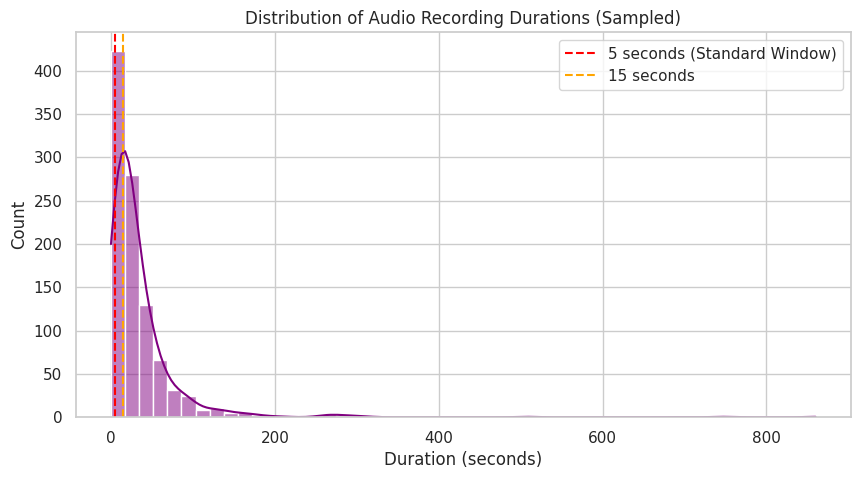

% of files < 5s: 9.3%
% of files > 15s: 62.3%

Durations vary a lot. Some are under 5 seconds, others are several minutes long.
We can't just use the first 5 seconds. For short files, use padding. For long files, extracting the highest energy segments is better.


In [5]:
# Sample a subset of files to estimate duration
np.random.seed(42)
sample_files = train.sample(1000)
durations = []

for _, row in tqdm(sample_files.iterrows(), total=len(sample_files), desc="Checking durations"):
    path1 = os.path.join(TRAIN_AUDIO_DIR, row['primary_label'], row['filename'])
    path2 = os.path.join(TRAIN_AUDIO_DIR, row['filename'])
    file_path = path1 if os.path.exists(path1) else path2
    
    try:
        if os.path.exists(file_path):
            info = sf.info(file_path)
            durations.append(info.duration)
    except Exception:
        pass

plt.figure(figsize=(10, 5))
sns.histplot(durations, bins=50, kde=True, color='purple')
plt.axvline(x=5, color='red', linestyle='--', label='5 seconds (Standard Window)')
plt.axvline(x=15, color='orange', linestyle='--', label='15 seconds')
plt.title("Distribution of Audio Recording Durations (Sampled)")
plt.xlabel("Duration (seconds)")
plt.ylabel("Count")
plt.legend()
plt.show()

d_arr = np.array(durations)
print(f"% of files < 5s: {(d_arr < 5).mean()*100:.1f}%")
print(f"% of files > 15s: {(d_arr > 15).mean()*100:.1f}%")
print("\nDurations vary a lot. Some are under 5 seconds, others are several minutes long.")
print("We can't just use the first 5 seconds. For short files, use padding. For long files, extracting the highest energy segments is better.")


## 4. Visualizing the Acoustic Feature Space
Visualizing audio in the frequency domain using Mel Spectrograms.


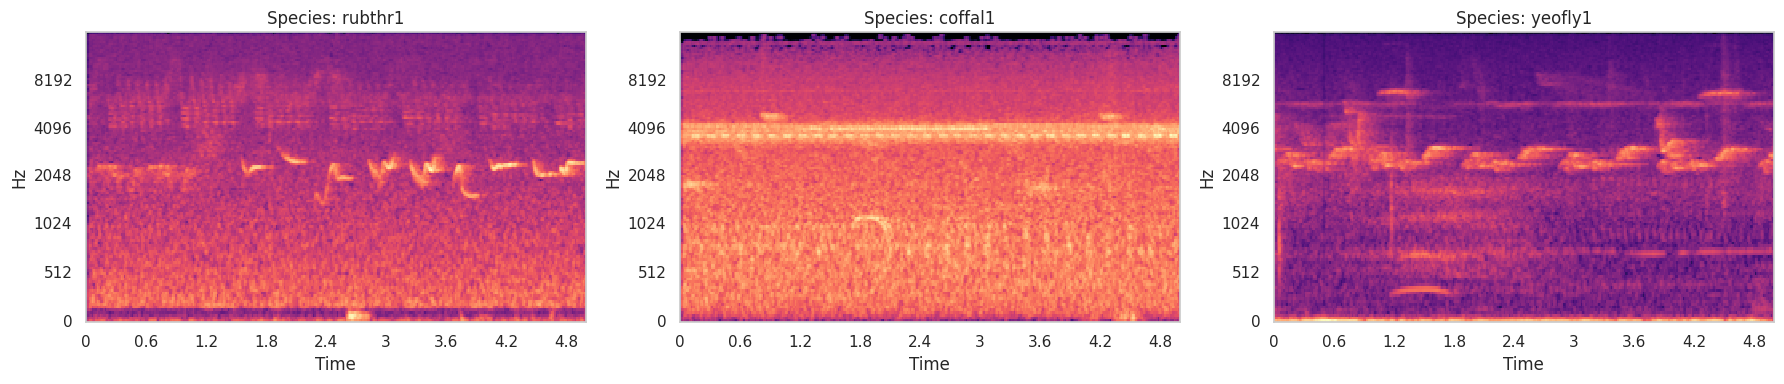

Bird calls show distinct shapes and textures on the spectrogram.
Since spectrograms are like images, CV features (HOG, GLCM) could be effective alongside acoustic features.


In [6]:
def plot_spectrogram(file_path, ax, title):
    try:
        y, sr = librosa.load(file_path, sr=32000, duration=5.0)
        S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=16000)
        S_dB = librosa.power_to_db(S, ref=np.max)
        img = librosa.display.specshow(S_dB, x_axis='time', y_axis='mel', sr=sr, fmax=16000, ax=ax)
        ax.set_title(title)
        return img
    except Exception as e:
        ax.set_title("Error loading audio")

top_species = train['primary_label'].value_counts().head(10).index
selected_species = [top_species[0], top_species[5], top_species[9]]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for i, species in enumerate(selected_species):
    sample = train[train['primary_label'] == species].iloc[0]
    p1 = os.path.join(TRAIN_AUDIO_DIR, sample['primary_label'], sample['filename'])
    p2 = os.path.join(TRAIN_AUDIO_DIR, sample['filename'])
    path = p1 if os.path.exists(p1) else p2
    plot_spectrogram(path, axes[i], f"Species: {species}")

plt.tight_layout()
plt.show()

print("Bird calls show distinct shapes and textures on the spectrogram.")
print("Since spectrograms are like images, CV features (HOG, GLCM) could be effective alongside acoustic features.")


## 5. Geographic Distribution Analysis
Checking spatial distribution of recordings.


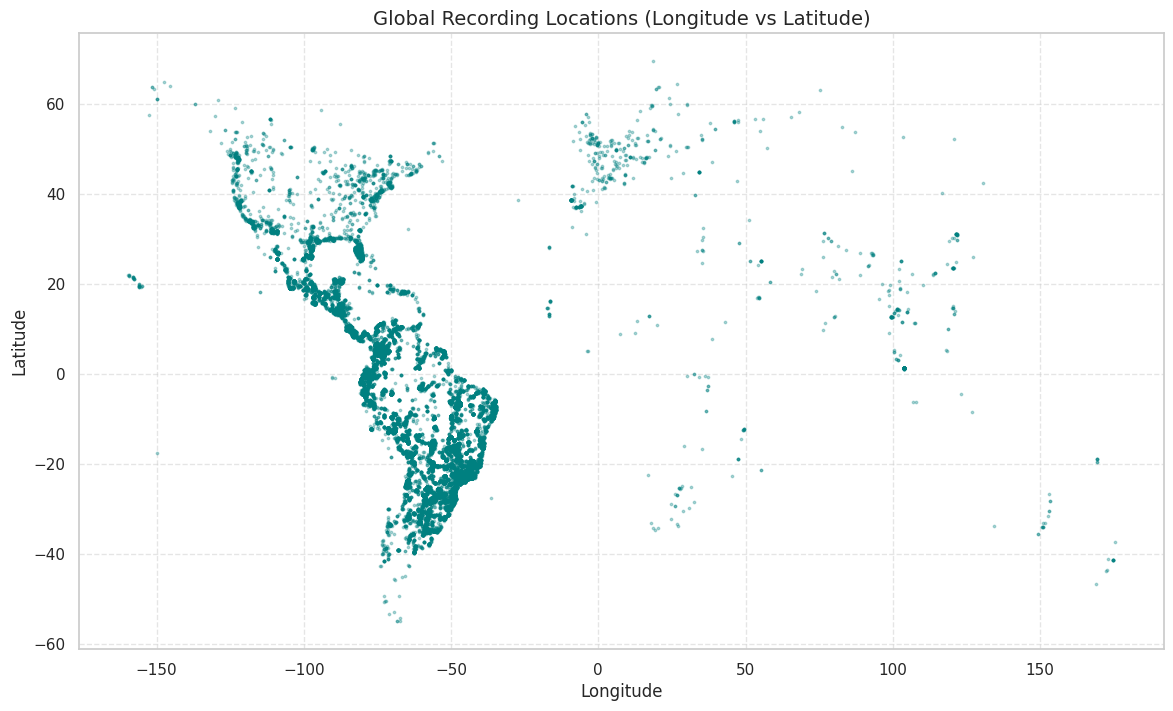

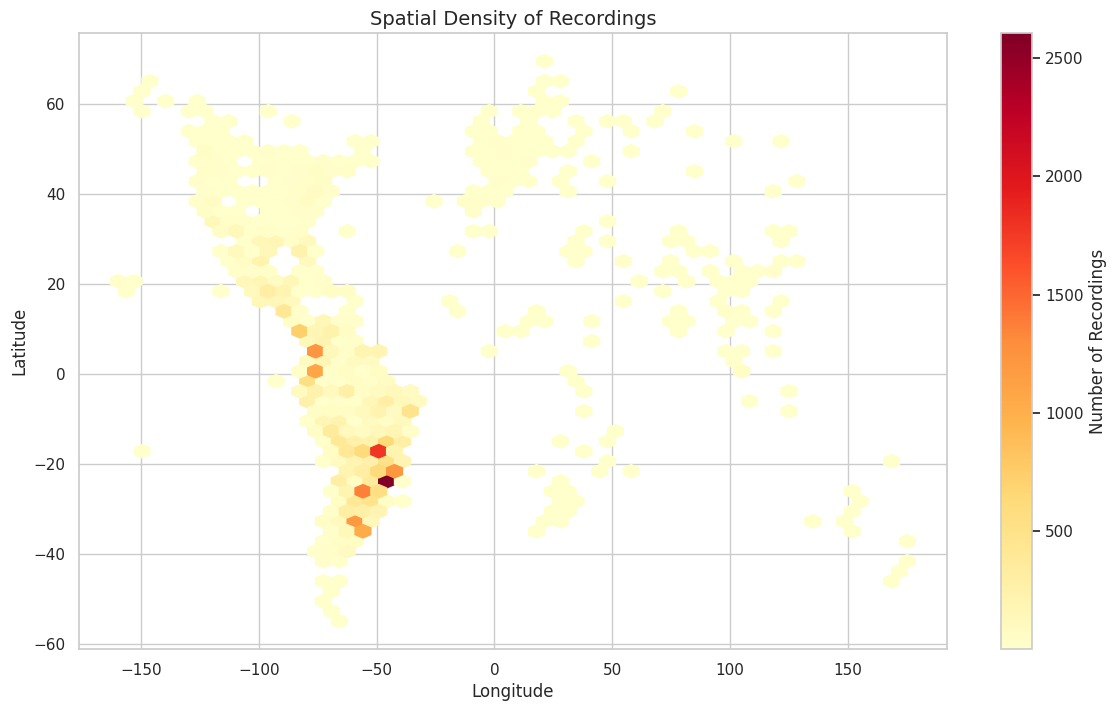

Recordings are clustered geographically. Some regions have lots of data, others have none.
This spatial bias means the model might overfit to specific regions' backgrounds. Using Site IDs could help calibrate predictions.


In [7]:
# Drop rows with missing coordinates
geo_df = train.dropna(subset=['latitude', 'longitude']).copy()

# Plot the global distribution of recordings
plt.figure(figsize=(14, 8))
plt.scatter(
    geo_df['longitude'],
    geo_df['latitude'],
    s=3,
    alpha=0.3,
    c='teal'
)
plt.title("Global Recording Locations (Longitude vs Latitude)", fontsize=14)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Visualize Recording Density (Hexbin)
plt.figure(figsize=(14, 8))
hb = plt.hexbin(
    geo_df['longitude'],
    geo_df['latitude'],
    gridsize=50,
    cmap='YlOrRd',
    mincnt=1
)
cb = plt.colorbar(hb)
cb.set_label("Number of Recordings")
plt.title("Spatial Density of Recordings", fontsize=14)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

print("Recordings are clustered geographically. Some regions have lots of data, others have none.")
print("This spatial bias means the model might overfit to specific regions' backgrounds. Using Site IDs could help calibrate predictions.")


## 6. Exploring Data Augmentation Feasibility
In Section 2, we discovered a severe class imbalance, suggesting the need for data augmentation. A common technique is mixing foreground bird calls with background "soundscapes". 

Before adopting this, let's visually verify that adding background noise doesn't completely destroy the original bird call signal.


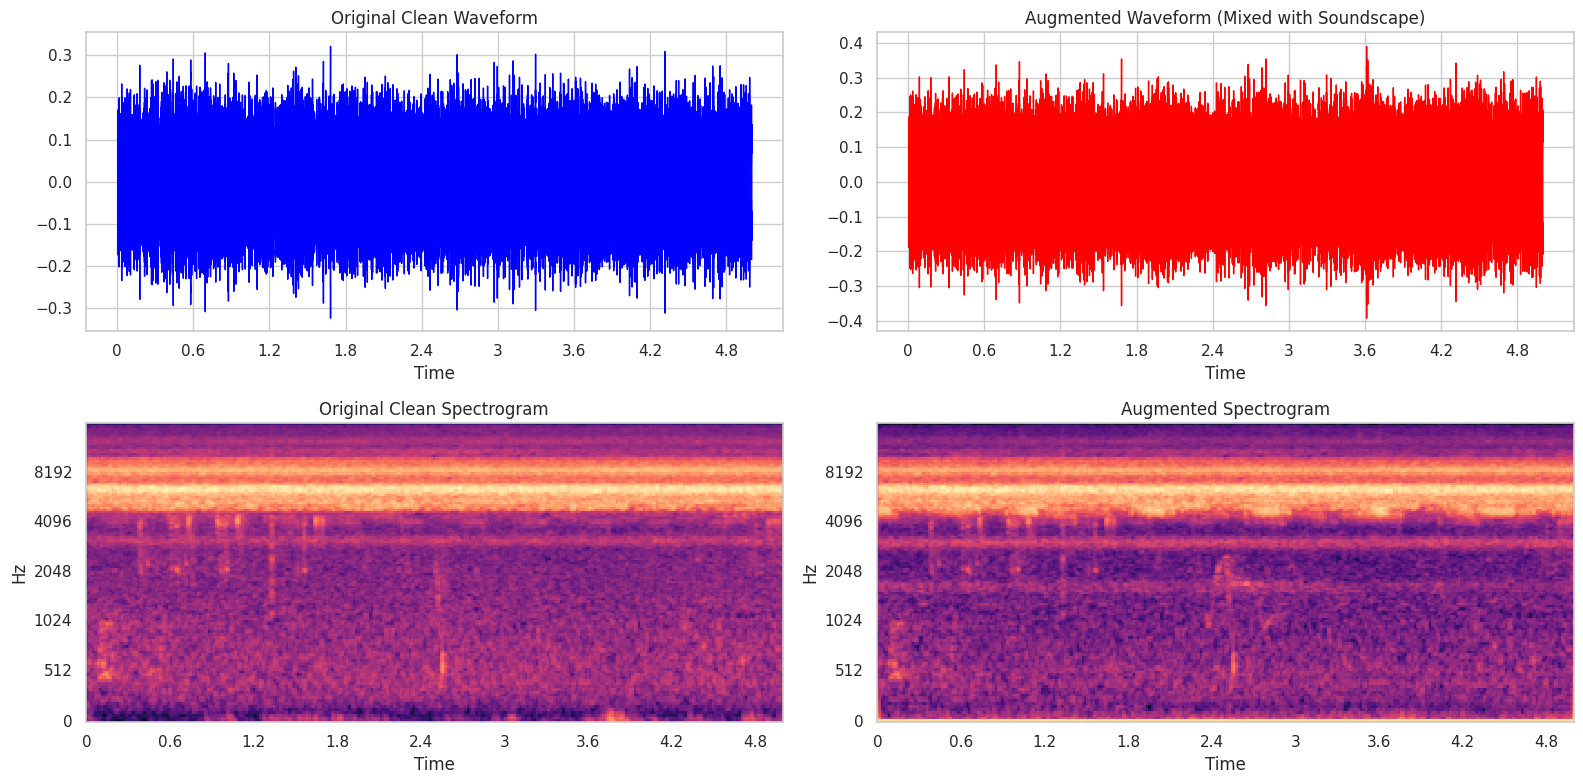

Background noise modifies the acoustic profile, but bird call frequencies are still visible.
Mixing rare bird calls with random soundscapes is a viable augmentation strategy.


In [8]:
def load_random_soundscape():
    if not os.path.exists(SOUNDSCAPE_DIR):
        return np.zeros(32000*5)
    files = list(Path(SOUNDSCAPE_DIR).glob('*.ogg'))
    if not files:
        return np.zeros(32000*5)
    try:
        y, _ = librosa.load(random.choice(files), sr=32000, duration=5.0)
        return y
    except:
        return np.zeros(32000*5)

sample_row = train[train['rating'] >= 4.0].iloc[0]
p1 = os.path.join(TRAIN_AUDIO_DIR, sample_row['primary_label'], sample_row['filename'])
p2 = os.path.join(TRAIN_AUDIO_DIR, sample_row['filename'])
clean_path = p1 if os.path.exists(p1) else p2

try:
    clean_audio, _ = librosa.load(clean_path, sr=32000, duration=5.0)
    noise_audio = load_random_soundscape()
    
    if len(noise_audio) < len(clean_audio):
        noise_audio = np.pad(noise_audio, (0, len(clean_audio) - len(noise_audio)), 'constant')
    else:
        noise_audio = noise_audio[:len(clean_audio)]
        
    # Mix at ~ 5dB SNR
    snr_db = 5.0
    clean_rms = np.sqrt(np.mean(clean_audio**2) + 1e-9)
    noise_rms = np.sqrt(np.mean(noise_audio**2) + 1e-9)
    scale = clean_rms / (noise_rms * (10 ** (snr_db / 20)))
    
    augmented_audio = clean_audio + noise_audio * scale
    if np.max(np.abs(augmented_audio)) > 1.0:
        augmented_audio /= np.max(np.abs(augmented_audio))
        
    fig, axes = plt.subplots(2, 2, figsize=(16, 8))
    
    librosa.display.waveshow(clean_audio, sr=32000, ax=axes[0,0], color='blue')
    axes[0,0].set_title("Original Clean Waveform")
    
    librosa.display.waveshow(augmented_audio, sr=32000, ax=axes[0,1], color='red')
    axes[0,1].set_title("Augmented Waveform (Mixed with Soundscape)")
    
    S_clean = librosa.power_to_db(librosa.feature.melspectrogram(y=clean_audio, sr=32000), ref=np.max)
    librosa.display.specshow(S_clean, sr=32000, x_axis='time', y_axis='mel', ax=axes[1,0])
    axes[1,0].set_title("Original Clean Spectrogram")
    
    S_aug = librosa.power_to_db(librosa.feature.melspectrogram(y=augmented_audio, sr=32000), ref=np.max)
    librosa.display.specshow(S_aug, sr=32000, x_axis='time', y_axis='mel', ax=axes[1,1])
    axes[1,1].set_title("Augmented Spectrogram")
    
    plt.tight_layout()
    plt.show()
    
    print("Background noise modifies the acoustic profile, but bird call frequencies are still visible.")
    print("Mixing rare bird calls with random soundscapes is a viable augmentation strategy.")
except Exception as e:
    print("Visualization skipped.", e)


## 7. Conclusions & Next Steps

Pipeline strategies:

1. **Handle Imbalance**: Class weights and noise augmentation.
2. **Quality Control**: Filter `rating < 2` samples.
3. **Segmentation**: Use energy-based window selection.
4. **Feature Set**: Combine standard acoustic and CV features.
5. **Geographic Priors**: Use Site IDs or coordinate priors.

